# Activation — TODO
Chưa thực hiện thí nghiệm. Giữ nguyên split seed 42; chỉ so sánh trên validation.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()

while not (ROOT / "source" / "config.py").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Project root not found")

    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import torch

from source.activations import (
    activation_forward,
    activation_derivative
)

x = torch.tensor([-3., -2., -1., 0., 1., 2., 3.])

y = activation_forward(x, "relu")
dy = activation_derivative(x, "relu")

print("Input:", x)
print("ReLU:", y)
print("Derivative:", dy)

Input: tensor([-3., -2., -1.,  0.,  1.,  2.,  3.])
ReLU: tensor([0., 0., 0., 0., 1., 2., 3.])
Derivative: tensor([0., 0., 0., 0., 1., 1., 1.])


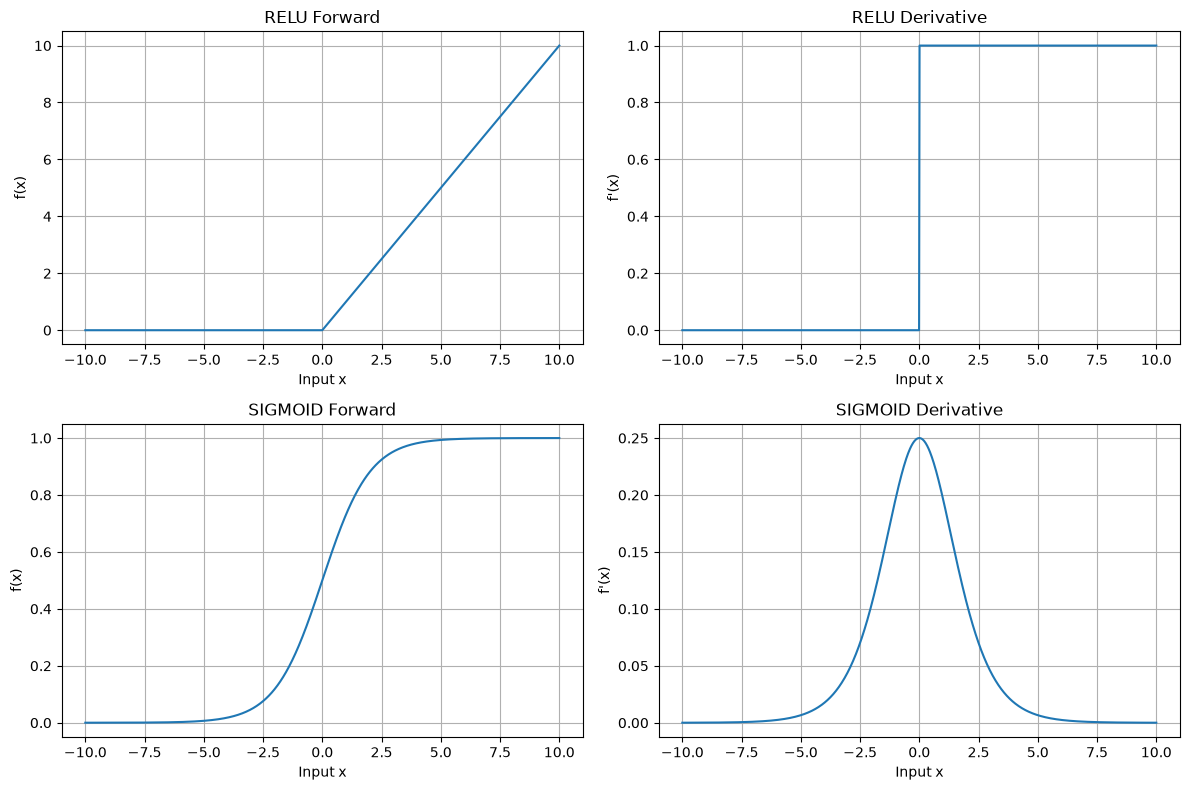

Saved: /home/kjwyy/Documents/code/IMGproccess/BT-TH/ImageProcessing_Lab02/results/figures/activation_functions.png


In [3]:
import torch
import matplotlib.pyplot as plt

from source.activations import (
    activation_forward,
    activation_derivative
)

x = torch.linspace(-10, 10, 1000)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, name in enumerate(["relu", "sigmoid"]):

    y = activation_forward(x, name)
    dy = activation_derivative(x, name)

    axes[i, 0].plot(x.numpy(), y.numpy())
    axes[i, 0].set_title(f"{name.upper()} Forward")
    axes[i, 0].set_xlabel("Input x")
    axes[i, 0].set_ylabel("f(x)")
    axes[i, 0].grid(True)

    axes[i, 1].plot(x.numpy(), dy.numpy())
    axes[i, 1].set_title(f"{name.upper()} Derivative")
    axes[i, 1].set_xlabel("Input x")
    axes[i, 1].set_ylabel("f'(x)")
    axes[i, 1].grid(True)

fig.tight_layout()

# Save figure
output_path = ROOT / "results/figures/activation_functions.png"

output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

# Display figure
plt.show()

print("Saved:", output_path)

In [4]:
import torch

x = torch.tensor([
    -1000., -100., -10.,
    -2., 0., 2.,
    10., 100., 1000.
])

for name in ["relu", "sigmoid"]:

    y = activation_forward(x, name)
    dy = activation_derivative(x, name)

    assert y.shape == x.shape
    assert dy.shape == x.shape

    assert torch.isfinite(y).all()
    assert torch.isfinite(dy).all()

    reference = (
        torch.relu(x)
        if name == "relu"
        else torch.sigmoid(x)
    )

    assert torch.allclose(y, reference, atol=1e-6)

    print(f"{name}: PASS")

relu: PASS
sigmoid: PASS


In [5]:
x = torch.tensor(
    [-1000., -100., 0., 100., 1000.],
    requires_grad=True
)

y = activation_forward(x, "sigmoid")

y.sum().backward()

assert torch.isfinite(x.grad).all()

print("Gradient:", x.grad)
print("Numerical Stability: PASS")

Gradient: tensor([0.0000e+00, 3.7835e-44, 2.5000e-01, 3.7835e-44, 0.0000e+00])
Numerical Stability: PASS


In [6]:
from source.activations import CustomActivation

x = torch.tensor(
    [-2., 0., 3.],
    requires_grad=True
)

activation = CustomActivation("relu")

y = activation(x)

loss = y.sum()

loss.backward()

print("Input:", x)
print("Output:", y)
print("Gradient:", x.grad)

Input: tensor([-2.,  0.,  3.], requires_grad=True)
Output: tensor([0., 0., 3.], grad_fn=<CustomActivationFunctionBackward>)
Gradient: tensor([0., 0., 1.])


In [7]:
x = torch.tensor(
    [-2., 0., 3.],
    requires_grad=True
)

y = CustomActivation("relu")(x)

y.backward(
    torch.tensor([2., 4., 6.])
)

print(x.grad)

tensor([0., 0., 6.])


In [8]:
assert torch.equal(
    x.grad,
    torch.tensor([0., 0., 6.])
)

print("Chain Rule: PASS")

Chain Rule: PASS


In [9]:
for name in ["relu", "sigmoid"]:

    x1 = torch.linspace(
        -10, 10, 101
    ).requires_grad_()

    x2 = x1.detach().clone().requires_grad_()

    # Custom implementation
    y1 = CustomActivation(name)(x1)

    # PyTorch reference
    if name == "relu":
        y2 = torch.relu(x2)
    else:
        y2 = torch.sigmoid(x2)

    y1.sum().backward()
    y2.sum().backward()

    assert torch.allclose(
        y1, y2, atol=1e-6
    )

    assert torch.allclose(
        x1.grad, x2.grad, atol=1e-6
    )

    print(f"{name}: Forward & Backward PASS")

relu: Forward & Backward PASS
sigmoid: Forward & Backward PASS


In [10]:
from torch.autograd import gradcheck

from source.activations import CustomActivationFunction

for name in ["relu", "sigmoid"]:

    x = torch.tensor(
        [-2.0, -0.5, 0.5, 2.0],
        dtype=torch.float64,
        requires_grad=True
    )

    passed = gradcheck(
        lambda x: CustomActivationFunction.apply(x, name),
        (x,),
        eps=1e-6,
        atol=1e-5
    )

    assert passed

    print(f"{name} Gradcheck: PASS")

relu Gradcheck: PASS
sigmoid Gradcheck: PASS
